**importing required libraries**

In [150]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from scipy.stats import spearmanr
from scipy.stats import kruskal
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from scipy.stats import randint, uniform
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
import copy
import joblib


**loading the dataset**

In [3]:
prod_demand_forecast_df = pd.read_csv(
    '/kaggle/input/datasets/jmwangi7/product-demand-forecast/pharmacy_forecasting_analysis_data.csv'
)

In [4]:
prod_demand_forecast_df.shape

(631800, 12)

**Basic_checks**

In [5]:
def basic_check(df):
    print(50*'=','DataSet Shape',50*'=')
    print(df.shape)
    print(50*'=','Variables Dtypes',50*'=')
    print(df.info())
    print(50*'=','Checking for dataset duplication',50*'=')
    print(df.duplicated().sum())
    print(50*'=','checking for dataset missingness',50*'=')
    print(df.isna().sum())
    print(50*'=','checking for dataset percentage missingness',50*'=')
    print((df.isna().sum()/len(df))*100)
    print('=' * 50, 'Statistical Summary', '=' * 50)
    display(df.describe().T)
    print('=' * 50, 'Categorical Summary', '=' * 50)
    display(df.describe(include=['object', 'category']).T)

In [6]:
basic_check(prod_demand_forecast_df)

================================================== DataSet Shape ==================================================
(631800, 12)
================================================== Variables Dtypes ==================================================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 631800 entries, 0 to 631799
Data columns (total 12 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   sales_date                 631800 non-null  object 
 1   store_id                   631800 non-null  object 
 2   product_id                 631800 non-null  object 
 3   units_sold                 631800 non-null  int64  
 4   unfulfilled_units          631800 non-null  int64  
 5   day_of_week                631800 non-null  int64  
 6   sales_month                631800 non-null  int64  
 7   is_weekend                 631800 non-null  int64  
 8   sales_previous_day         631800 non-null  int64  
 9   sales_pre

,count,mean,std,min,25%,50%,75%,max
units_sold,631800.0,0.474186,0.941794,0.0,0.000000,0.000000,1.000000,17.000000
unfulfilled_units,631800.0,0.003940,0.096350,0.0,0.000000,0.000000,0.000000,15.000000
day_of_week,631800.0,3.997151,1.997862,1.0,2.000000,4.000000,6.000000,7.000000
sales_month,631800.0,6.527066,3.339950,1.0,4.000000,7.000000,9.000000,12.000000
is_weekend,631800.0,0.284900,0.451367,0.0,0.000000,0.000000,1.000000,1.000000
sales_previous_day,631800.0,0.473769,0.941474,0.0,0.000000,0.000000,1.000000,17.000000
sales_previous_week,631800.0,0.470601,0.937066,0.0,0.000000,0.000000,1.000000,17.000000
avg_sales_previous_7_days,631800.0,0.472011,0.506773,0.0,0.142857,0.285714,0.714286,7.142857
target_next_7_days,631800.0,3.326488,3.574000,0.0,1.000000,2.000000,5.000000,50.000000


================================================== Categorical Summary ==================================================


,count,unique,top,freq
sales_date,631800,351,2025-12-24,1800
store_id,631800,12,ST01,52650
product_id,631800,150,P001,4212


**cleaning the date_column**
- date column is in str
  - converting to correct date format

In [7]:
prod_demand_forecast_df['sales_date'] = pd.to_datetime(prod_demand_forecast_df['sales_date'],format='mixed',errors='coerce')
prod_demand_forecast_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 631800 entries, 0 to 631799
Data columns (total 12 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   sales_date                 631800 non-null  datetime64[ns]
 1   store_id                   631800 non-null  object        
 2   product_id                 631800 non-null  object        
 3   units_sold                 631800 non-null  int64         
 4   unfulfilled_units          631800 non-null  int64         
 5   day_of_week                631800 non-null  int64         
 6   sales_month                631800 non-null  int64         
 7   is_weekend                 631800 non-null  int64         
 8   sales_previous_day         631800 non-null  int64         
 9   sales_previous_week        631800 non-null  int64         
 10  avg_sales_previous_7_days  631800 non-null  float64       
 11  target_next_7_days         631800 non-null  int64   

## Statistical Explorartive Analysis(SEA)

**Descriptive statitics**

In [8]:
prod_demand_forecast_df.describe().T

,count,mean,min,25%,50%,75%,max,std
sales_date,631800,2025-07-01 23:59:59.999999488,2025-01-08 00:00:00,2025-04-05 00:00:00,2025-07-02 00:00:00,2025-09-28 00:00:00,2025-12-24 00:00:00,NaN
units_sold,631800.0,0.474186,0.0,0.0,0.0,1.0,17.0,0.941794
unfulfilled_units,631800.0,0.00394,0.0,0.0,0.0,0.0,15.0,0.09635
day_of_week,631800.0,3.997151,1.0,2.0,4.0,6.0,7.0,1.997862
sales_month,631800.0,6.527066,1.0,4.0,7.0,9.0,12.0,3.33995
is_weekend,631800.0,0.2849,0.0,0.0,0.0,1.0,1.0,0.451367
sales_previous_day,631800.0,0.473769,0.0,0.0,0.0,1.0,17.0,0.941474
sales_previous_week,631800.0,0.470601,0.0,0.0,0.0,1.0,17.0,0.937066
avg_sales_previous_7_days,631800.0,0.472011,0.0,0.142857,0.285714,0.714286,7.142857,0.506773
target_next_7_days,631800.0,3.326488,0.0,1.0,2.0,5.0,50.0,3.574


**Calculating zero-sales and non-zero-sales frequencies**

In [9]:

total_records = len(prod_demand_forecast_df)

zero_sales_records = len((prod_demand_forecast_df[prod_demand_forecast_df['units_sold'] == 0]))
nonzero_sales_records = len((prod_demand_forecast_df[prod_demand_forecast_df['units_sold'] > 0]))

zero_sales_pct = (zero_sales_records / total_records) * 100
nonzero_sales_pct = (nonzero_sales_records / total_records) * 100

print(f"Total records: {total_records:,}")
print(f"Zero-sales records: {zero_sales_records:,} ({zero_sales_pct:.2f}%)")
print(f"Non-zero-sales records: {nonzero_sales_records:,} ({nonzero_sales_pct:.2f}%)")



Total records: 631,800
Zero-sales records: 453,047 (71.71%)
Non-zero-sales records: 178,753 (28.29%)


**Calculate the frequency distribution of daily sales quantities**

In [10]:
daily_sales_frequency = prod_demand_forecast_df['units_sold'].value_counts().sort_index()
daily_sales_percentage = (daily_sales_frequency / len(prod_demand_forecast_df)) * 100

sales_distribution = pd.DataFrame({
    'frequency': daily_sales_frequency,
    'percentage': daily_sales_percentage
})

sales_distribution


,frequency,percentage
units_sold,,
0,453047,71.707344
1,105275,16.662710
2,45255,7.162868
3,17067,2.701330
4,6579,1.041311
5,2661,0.421178
6,1090,0.172523
7,469,0.074232
8,182,0.028807


**Visualise the frequency distribution of daily sales**

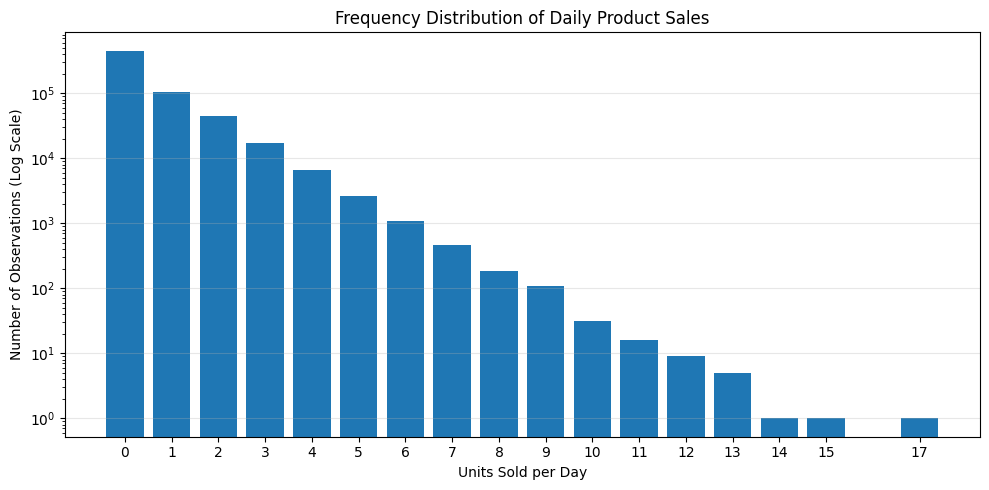

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(sales_distribution.index, sales_distribution['frequency'])
plt.yscale('log')
plt.title('Frequency Distribution of Daily Product Sales')
plt.xlabel('Units Sold per Day')
plt.ylabel('Number of Observations (Log Scale)')
plt.xticks(sales_distribution.index)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Examining the distribution of the seven-day demand target**

In [12]:
target_frequency = (prod_demand_forecast_df['target_next_7_days'].value_counts().sort_index())

target_percentage = (target_frequency / len(prod_demand_forecast_df)) * 100

target_distribution = pd.DataFrame({
    'frequency': target_frequency,
    'percentage': target_percentage
})

target_distribution

,frequency,percentage
target_next_7_days,,
0,114274,18.087053
1,115273,18.245173
2,101084,15.999367
3,79197,12.535138
4,59039,9.344571
5,43317,6.856125
6,30672,4.854701
7,22539,3.567426
8,16477,2.607946


**Visualise the seven-day demand distribution**

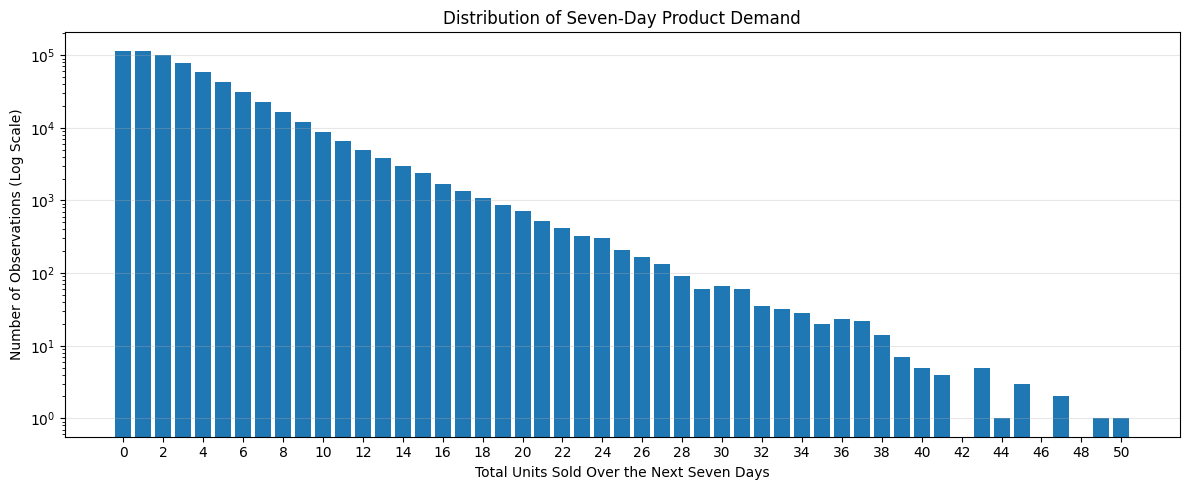

In [13]:
plt.figure(figsize=(12, 5))
plt.bar(target_distribution.index,target_distribution['frequency'])
plt.yscale('log')
plt.title('Distribution of Seven-Day Product Demand')
plt.xlabel('Total Units Sold Over the Next Seven Days')
plt.ylabel('Number of Observations (Log Scale)')
plt.xticks(range(0, 51, 2))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Descriptive statistics of the seven-day demand target**

In [14]:
target_stats = prod_demand_forecast_df['target_next_7_days'].describe()

print(target_stats)

print("\nAdditional statistics:")
print("Variance:", prod_demand_forecast_df['target_next_7_days'].var())
print("Skewness:", prod_demand_forecast_df['target_next_7_days'].skew())
print("Kurtosis:", prod_demand_forecast_df['target_next_7_days'].kurt())

count    631800.000000
mean          3.326488
std           3.574000
min           0.000000
25%           1.000000
50%           2.000000
75%           5.000000
max          50.000000
Name: target_next_7_days, dtype: float64

Additional statistics:
Variance: 12.773478157549567
Skewness: 2.2628688869121514
Kurtosis: 8.474370815205914


**Summarising demand patterns for each product-branch combination**

In [15]:
product_branch_stats = ( prod_demand_forecast_df.groupby(['store_id', 'product_id'])
    .agg(
        avg_daily_sales=('units_sold', 'mean'),
        std_daily_sales=('units_sold', 'std'),
        zero_sales_pct=('units_sold', lambda x: (x == 0).mean() * 100),
        avg_next_7_days=('target_next_7_days', 'mean')
    ).reset_index())

product_branch_stats.describe().T

,count,mean,std,min,25%,50%,75%,max
avg_daily_sales,1800.0,0.474186,0.387814,0.048433,0.222222,0.358974,0.586895,3.501425
std_daily_sales,1800.0,0.793298,0.330911,0.227889,0.557394,0.726850,0.953199,2.585536
zero_sales_pct,1800.0,71.707344,15.731014,6.267806,63.817664,75.498575,83.760684,96.011396
avg_next_7_days,1800.0,3.326488,2.721175,0.339031,1.569801,2.525641,4.115385,24.689459


**Identifying the 10 highest demand product-branch combinations**

In [16]:

product_branch_stats.sort_values(by='avg_daily_sales',ascending=False).head(10)

,store_id,product_id,avg_daily_sales,std_daily_sales,zero_sales_pct,avg_next_7_days
61,ST01,P062,3.501425,2.585536,6.267806,24.689459
1200,ST09,P001,3.481481,2.430538,7.692308,24.433048
450,ST04,P001,3.059829,2.308830,10.541311,21.601140
0,ST01,P001,2.672365,2.178677,17.094017,18.843305
150,ST02,P001,2.529915,2.019502,15.384615,17.860399
228,ST02,P079,2.518519,1.954942,14.245014,17.575499
1261,ST09,P062,2.509972,2.051978,16.239316,17.609687
961,ST07,P062,2.490028,1.979693,16.239316,17.584046
811,ST06,P062,2.418803,1.995306,16.809117,16.945869
361,ST03,P062,2.227920,1.906205,17.663818,15.623932


In [17]:
product_branch_stats

,store_id,product_id,avg_daily_sales,std_daily_sales,zero_sales_pct,avg_next_7_days
0,ST01,P001,2.672365,2.178677,17.094017,18.843305
1,ST01,P002,0.572650,0.931815,65.242165,3.982906
2,ST01,P003,1.356125,1.466273,35.897436,9.504274
3,ST01,P004,0.490028,0.813660,65.242165,3.373219
4,ST01,P005,0.555556,1.000952,67.236467,3.880342
...,...,...,...,...,...,...
1795,ST12,P146,0.222222,0.572380,84.045584,1.572650
1796,ST12,P147,0.282051,0.648244,80.911681,2.002849
1797,ST12,P148,0.230769,0.551123,82.621083,1.581197
1798,ST12,P149,0.253561,0.628906,82.905983,1.806268


**Bottom 10 product-branch combinations by average daily sales**

In [18]:

product_branch_stats.sort_values(by='avg_daily_sales',ascending=True).head(10)

,store_id,product_id,avg_daily_sales,std_daily_sales,zero_sales_pct,avg_next_7_days
1077,ST08,P028,0.048433,0.227889,95.441595,0.339031
1079,ST08,P030,0.051282,0.256776,95.726496,0.358974
1749,ST12,P100,0.051282,0.256776,95.726496,0.358974
1569,ST11,P070,0.054131,0.292631,96.011396,0.381766
566,ST04,P117,0.056980,0.232135,94.301994,0.410256
479,ST04,P030,0.056980,0.244133,94.586895,0.398860
629,ST05,P030,0.059829,0.281545,95.156695,0.418803
1248,ST09,P049,0.062678,0.332184,96.011396,0.461538
871,ST06,P122,0.065527,0.290285,94.586895,0.447293
560,ST04,P111,0.071225,0.278872,93.447293,0.521368


**Average daily sales by day of the week**

In [19]:


weekday_demand = (prod_demand_forecast_df
    .groupby('day_of_week')['units_sold']
    .agg(['mean', 'median', 'sum', 'count'])
    .reset_index())

weekday_demand

,day_of_week,mean,median,sum,count
0,1,0.486978,0.0,43828,90000
1,2,0.462444,0.0,41620,90000
2,3,0.471046,0.0,43242,91800
3,4,0.476411,0.0,42877,90000
4,5,0.505878,0.0,45529,90000
5,6,0.513267,0.0,46194,90000
6,7,0.403344,0.0,36301,90000


**Compare average daily sales on weekdays and weekends**

In [20]:
weekend_comparison = ( prod_demand_forecast_df
    .groupby('is_weekend')['units_sold']
    .agg(['mean', 'median', 'sum', 'count'])
    .reset_index()
)

weekend_comparison

,is_weekend,mean,median,sum,count
0,0,0.480514,0.0,217096,451800
1,1,0.458306,0.0,82495,180000


**Calculate weekday and weekend averages for each product-branch combination**

In [21]:
paired_demand = (prod_demand_forecast_df.groupby(['store_id', 'product_id', 'is_weekend'])['units_sold'].mean().unstack().reset_index())
paired_demand
paired_demand.columns.name = None

paired_demand = paired_demand.rename(columns={
    0: 'weekday_avg',
    1: 'weekend_avg'
})

paired_demand.head()

,store_id,product_id,weekday_avg,weekend_avg
0,ST01,P001,2.756972,2.46
1,ST01,P002,0.617530,0.46
2,ST01,P003,1.382470,1.29
3,ST01,P004,0.501992,0.46
4,ST01,P005,0.581673,0.49


**Compare weekday and weekend demand across matched combinations**

In [22]:
statistic, p_value = wilcoxon(
    paired_demand['weekday_avg'],
    paired_demand['weekend_avg'],
    alternative='two-sided'
)

print("Wilcoxon statistic:", statistic)
print("P-value:", p_value)

Wilcoxon statistic: 611760.0
P-value: 2.0792821916166944e-19


**convert day_of_week and sales_month categorical variable**

In [23]:
print('Day_of_week',prod_demand_forecast_df['day_of_week'].unique())
print('sales_month',prod_demand_forecast_df['sales_month'].unique())

Day_of_week [3 4 5 6 7 1 2]
sales_month [ 1  2  3  4  5  6  7  8  9 10 11 12]


In [24]:
# Map numerical weekdays to categorical names
day_mapping = {
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
}

# Map numerical months to categorical names
month_mapping = {
    1: 'January',
    2: 'February',
    3: 'March',
    4: 'April',
    5: 'May',
    6: 'June',
    7: 'July',
    8: 'August',
    9: 'September',
    10: 'October',
    11: 'November',
    12: 'December'
}

# Apply mappings
prod_demand_forecast_df['day_of_week'] = prod_demand_forecast_df['day_of_week'].map(day_mapping).astype('category')
prod_demand_forecast_df['sales_month'] = prod_demand_forecast_df['sales_month'].map(month_mapping).astype('category')

In [25]:
prod_demand_forecast_df

,sales_date,store_id,product_id,units_sold,unfulfilled_units,day_of_week,sales_month,is_weekend,sales_previous_day,sales_previous_week,avg_sales_previous_7_days,target_next_7_days
0,2025-01-08,ST01,P001,3,0,Wednesday,January,0,3,2,1.714286,16
1,2025-01-08,ST01,P002,2,0,Wednesday,January,0,0,0,0.857143,0
2,2025-01-08,ST01,P003,1,0,Wednesday,January,0,0,2,0.714286,12
3,2025-01-08,ST01,P004,2,0,Wednesday,January,0,0,1,0.571429,6
4,2025-01-08,ST01,P005,0,0,Wednesday,January,0,0,0,0.000000,2
...,...,...,...,...,...,...,...,...,...,...,...,...
631795,2025-12-24,ST12,P146,0,0,Wednesday,December,0,0,1,0.285714,3
631796,2025-12-24,ST12,P147,0,0,Wednesday,December,0,1,0,0.428571,4
631797,2025-12-24,ST12,P148,0,0,Wednesday,December,0,0,0,0.428571,1
631798,2025-12-24,ST12,P149,0,0,Wednesday,December,0,0,2,0.571429,4


**Examine correlations among numerical features and the forecast target**

In [26]:
# selecting numerical columns
num_cols = prod_demand_forecast_df.select_dtypes(include=['int','float']).columns.to_list()
num_cols

['units_sold',
 'unfulfilled_units',
 'is_weekend',
 'sales_previous_day',
 'sales_previous_week',
 'avg_sales_previous_7_days',
 'target_next_7_days']

In [27]:

correlation_matrix = prod_demand_forecast_df[num_cols].corr()

correlation_matrix.round(2)

,units_sold,unfulfilled_units,is_weekend,sales_previous_day,sales_previous_week,avg_sales_previous_7_days,target_next_7_days
units_sold,1.00,-0.00,-0.01,0.18,0.17,0.32,0.32
unfulfilled_units,-0.00,1.00,-0.00,0.01,0.02,0.03,0.01
is_weekend,-0.01,-0.00,1.00,0.02,-0.01,-0.00,-0.00
sales_previous_day,0.18,0.01,0.02,1.00,0.17,0.54,0.32
sales_previous_week,0.17,0.02,-0.01,0.17,1.00,0.54,0.31
avg_sales_previous_7_days,0.32,0.03,-0.00,0.54,0.54,1.00,0.58
target_next_7_days,0.32,0.01,-0.00,0.32,0.31,0.58,1.00


**Visualising the correlation matrix**

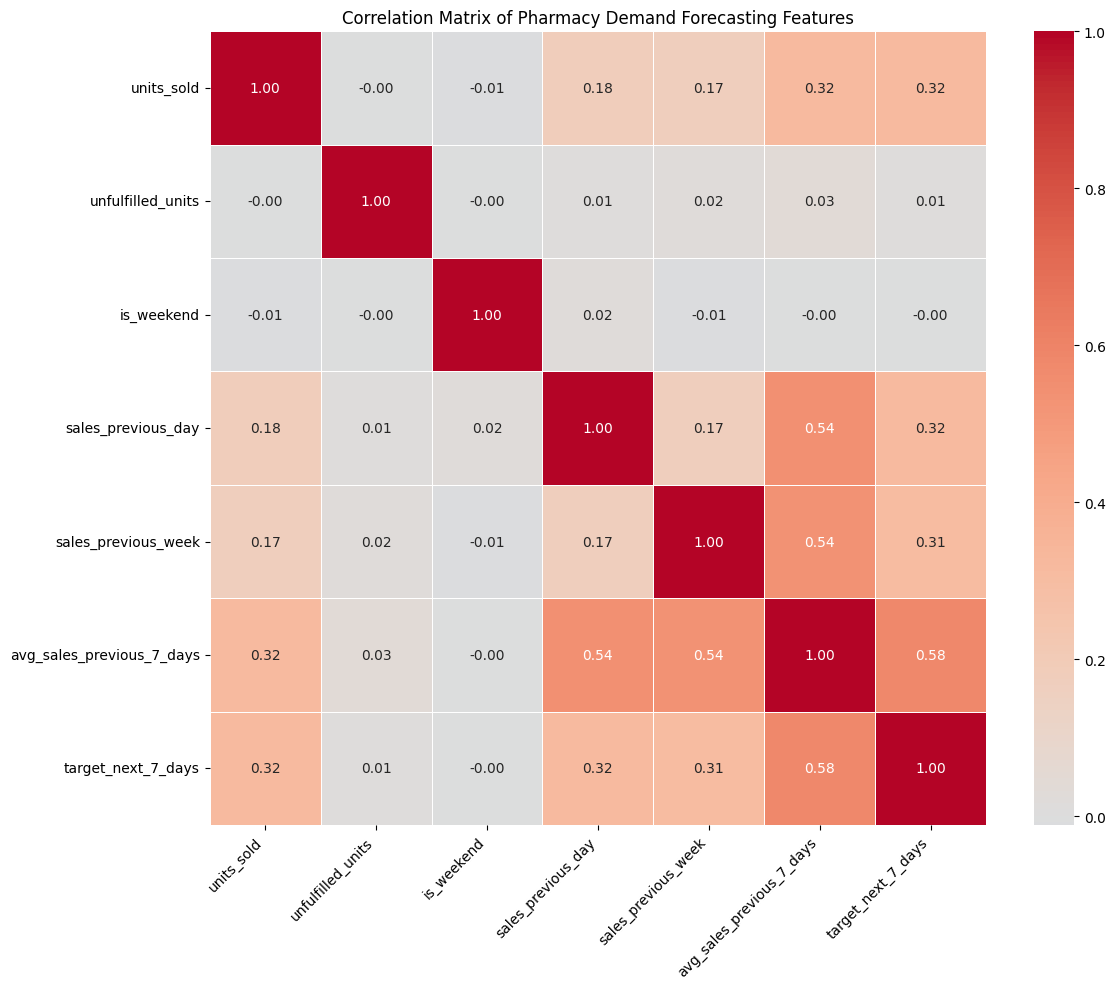

In [28]:
plt.figure(figsize=(12,10))
sns.heatmap(correlation_matrix,cmap='coolwarm',annot=True,fmt='.2f',linewidths=0.4,center=0)
plt.title('Correlation Matrix of Pharmacy Demand Forecasting Features')
plt.xticks(rotation=45,ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Note:**
- Values close to +1: Strong positive relationships.
- Values close to -1: Strong negative relationships.
- Values close to 0: Weak linear relationships.

**findings:**
- avg_sales_previous_7_days has the strongest relationship with our target (0.58).
- units_sold and sales_previous_day have moderate positive relationships with the target (0.32 each).
- sales_previous_week also has a moderate relationship (0.31).
- unfulfilled_units,have very weak linear relationships with the target.
- day_of_week and is_weekend are strongly correlated (0.79), so i should consider potential redundancy when selecting calendar features.

**Relationship between historical average sales and future demand**

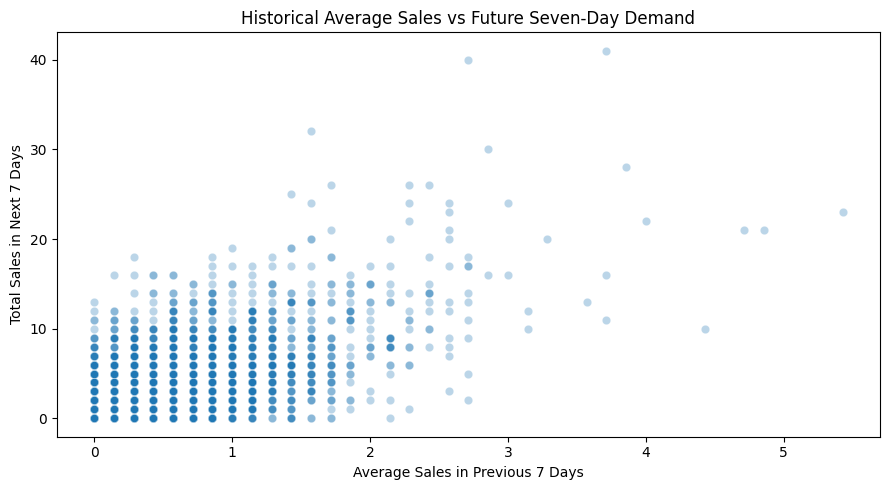

In [29]:

plt.figure(figsize=(9, 5))
sns.scatterplot(data=prod_demand_forecast_df.sample(5000, random_state=42),x='avg_sales_previous_7_days',y='target_next_7_days', alpha=0.3)
plt.title('Historical Average Sales vs Future Seven-Day Demand')
plt.xlabel('Average Sales in Previous 7 Days')
plt.ylabel('Total Sales in Next 7 Days')
plt.tight_layout()
plt.show()

**Historical sales in the previous week vs future demand**

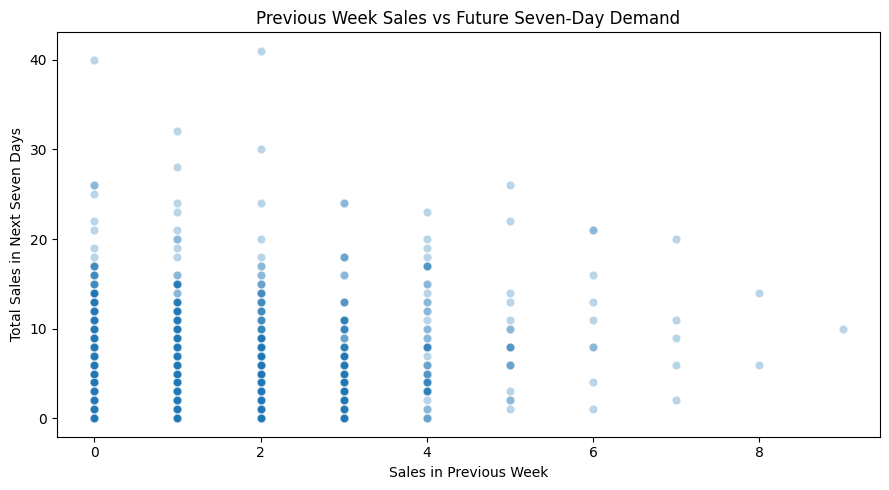

In [30]:
sample_df = prod_demand_forecast_df.sample(5000, random_state=42)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=sample_df,x='sales_previous_week', y='target_next_7_days',alpha=0.3)
plt.title('Previous Week Sales vs Future Seven-Day Demand')
plt.xlabel('Sales in Previous Week')
plt.ylabel('Total Sales in Next Seven Days')
plt.tight_layout()
plt.show()

In [31]:
# Check the number of records per date

daily_record_counts = (
    prod_demand_forecast_df
    .groupby('sales_date')
    .size()
)

print(daily_record_counts.describe())
print("\nMinimum records per date:", daily_record_counts.min())
print("Maximum records per date:", daily_record_counts.max())
print("Number of dates with unexpected records:",
      (daily_record_counts != 1800).sum())

count     351.0
mean     1800.0
std         0.0
min      1800.0
25%      1800.0
50%      1800.0
75%      1800.0
max      1800.0
dtype: float64

Minimum records per date: 1800
Maximum records per date: 1800
Number of dates with unexpected records: 0


**Spearman correlation analysis**

In [32]:

# Select numerical variables, excluding the date
numerical_df = prod_demand_forecast_df.select_dtypes(include=['int','float'])
# Calculate Spearman correlation coefficients and p-values
spearman_result = spearmanr(numerical_df)
spearman_correlation = pd.DataFrame(
    spearman_result.statistic,
    index=numerical_df.columns,
    columns=numerical_df.columns)

spearman_pvalues = pd.DataFrame(
    spearman_result.pvalue,
    index=numerical_df.columns,
    columns=numerical_df.columns)

# Display correlations with the forecasting target
print("Spearman correlations with target:")
print(spearman_correlation['target_next_7_days'].sort_values(ascending=False))

print("\nCorresponding p-values:")
print(
    spearman_pvalues['target_next_7_days'] .sort_values())

Spearman correlations with target:
target_next_7_days           1.000000
avg_sales_previous_7_days    0.451989
units_sold                   0.247308
sales_previous_day           0.245169
sales_previous_week          0.240882
unfulfilled_units           -0.000638
is_weekend                  -0.001009
Name: target_next_7_days, dtype: float64

Corresponding p-values:
units_sold                   0.000000
sales_previous_day           0.000000
avg_sales_previous_7_days    0.000000
sales_previous_week          0.000000
target_next_7_days           0.000000
is_weekend                   0.422706
unfulfilled_units            0.612072
Name: target_next_7_days, dtype: float64


**examining distribution across weekdays**

In [33]:
# Number of observations per weekday
prod_demand_forecast_df.groupby('day_of_week', observed=True)['target_next_7_days'].agg(
    ['count', 'mean', 'median', 'std'])

,count,mean,median,std
day_of_week,,,,
Friday,90000,3.322044,2.0,3.572488
Monday,90000,3.325589,2.0,3.567948
Saturday,90000,3.324467,2.0,3.578065
Sunday,90000,3.322078,2.0,3.573314
Thursday,90000,3.322267,2.0,3.567865
Tuesday,90000,3.330778,2.0,3.573653
Wednesday,91800,3.337963,2.0,3.584517


**The kruskal wallis test**

In [34]:
# weekday order
weekdays = ['Monday', 'Tuesday', 'Wednesday','Thursday', 'Friday', 'Saturday', 'Sunday']
# Extract sales demand for each weekday
weekday_groups = []

for day in weekdays:

    group = prod_demand_forecast_df.loc[
        prod_demand_forecast_df['day_of_week'] == day,
        'target_next_7_days'
    ].dropna()

    weekday_groups.append(group)

# significance level
alpha = 0.05
# hypothesis
H0 = 'The distribution of demand is the same across all weekdays.'
H1 = 'At least one weekday has a different demand distribution'
# Kruskal-Wallis test
h_stat, p_value = kruskal(*weekday_groups)

#results
print(f'H-statistic: {h_stat:.4f}')
print(f'P-value: {p_value:.6f}')

# Decision
if p_value < alpha:
    print(f"Reject: {H0}")
else:
    print(F"Fail to reject: {H0}")

H-statistic: 1.8700
P-value: 0.931260
Fail to reject: The distribution of demand is the same across all weekdays.


In [35]:
prod_demand_forecast_df.columns.to_list()

['sales_date',
 'store_id',
 'product_id',
 'units_sold',
 'unfulfilled_units',
 'day_of_week',
 'sales_month',
 'is_weekend',
 'sales_previous_day',
 'sales_previous_week',
 'avg_sales_previous_7_days',
 'target_next_7_days']

In [36]:

# Month order
months = ['January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December']

#sales demand for each month
month_groups = []

for month in months:
    group = prod_demand_forecast_df.loc[
        prod_demand_forecast_df['sales_month'] == month,
        'target_next_7_days'
    ].dropna()

    month_groups.append(group)

# Significance level
alpha = 0.05

# Hypotheses
H0 = 'The distribution of demand is the same across all twelve months.'
H1 = 'At least one month has a different demand distribution.'

# Kruskal-Wallis test
h_stat, p_value = kruskal(*month_groups)

# Statistical decision
if p_value < alpha:
    print(f'\nDecision: Reject H0: {H0}')
    print('Conclusion: There is sufficient evidence that demand distributions differ across months.')
else:
    print(f'\nDecision: Fail to reject H0: {H0}')
    print('Conclusion: There is insufficient evidence that demand distributions differ across months.')



Decision: Reject H0: The distribution of demand is the same across all twelve months.
Conclusion: There is sufficient evidence that demand distributions differ across months.


In [37]:
print("Number of stores:", prod_demand_forecast_df['store_id'].nunique())
print("Number of products:", prod_demand_forecast_df['product_id'].nunique())

Number of stores: 12
Number of products: 150


## Modelling Data Preparation

**establish the training, validation and test periods**
- i will use a `70% ` `15%` `15%`  chronological allocation, with six excluded dates between each partition to prevent overlapping seven-day target windows.

**Identify chronological split boundaries**

In [38]:
unique_dates = sorted(prod_demand_forecast_df['sales_date'].unique())
n_dates = len(unique_dates)
train_set_end = int(n_dates * 0.70)
validation_set_end = int(n_dates * 0.85)

print("Total dates:", n_dates)
print("Training period:", unique_dates[0], "to", unique_dates[train_set_end - 1])
print("Validation period:", unique_dates[train_set_end + 6], "to", unique_dates[validation_set_end - 1])
print("Testing period:", unique_dates[validation_set_end + 6], "to", unique_dates[-1])

Total dates: 351
Training period: 2025-01-08 00:00:00 to 2025-09-09 00:00:00
Validation period: 2025-09-16 00:00:00 to 2025-11-01 00:00:00
Testing period: 2025-11-08 00:00:00 to 2025-12-24 00:00:00


In [39]:
prod_demand_forecast_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 631800 entries, 0 to 631799
Data columns (total 12 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   sales_date                 631800 non-null  datetime64[ns]
 1   store_id                   631800 non-null  object        
 2   product_id                 631800 non-null  object        
 3   units_sold                 631800 non-null  int64         
 4   unfulfilled_units          631800 non-null  int64         
 5   day_of_week                631800 non-null  category      
 6   sales_month                631800 non-null  category      
 7   is_weekend                 631800 non-null  int64         
 8   sales_previous_day         631800 non-null  int64         
 9   sales_previous_week        631800 non-null  int64         
 10  avg_sales_previous_7_days  631800 non-null  float64       
 11  target_next_7_days         631800 non-null  int64   

In [40]:
unique_dates[-1]

Timestamp('2025-12-24 00:00:00')

### Creating chronological training, validation and testing datasets

In [41]:
train_df = prod_demand_forecast_df[prod_demand_forecast_df['sales_date'] <= unique_dates[train_set_end - 1]].copy()

validation_df = prod_demand_forecast_df[(prod_demand_forecast_df['sales_date'] >= unique_dates[train_set_end + 6]) &
                                        (prod_demand_forecast_df['sales_date'] <= unique_dates[validation_set_end - 1])].copy()

test_df = prod_demand_forecast_df[prod_demand_forecast_df['sales_date'] >= unique_dates[validation_set_end + 6]].copy()

print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (441000, 12)
Validation shape: (84600, 12)
Testing shape: (84600, 12)


In [42]:
train_df.columns.to_list()

['sales_date',
 'store_id',
 'product_id',
 'units_sold',
 'unfulfilled_units',
 'day_of_week',
 'sales_month',
 'is_weekend',
 'sales_previous_day',
 'sales_previous_week',
 'avg_sales_previous_7_days',
 'target_next_7_days']

**What i will use as my initial model features and target**

In [43]:
feature_columns = [
    'store_id',
    'product_id',
    'units_sold',
    'day_of_week',
    'sales_month',
    'sales_previous_day',
    'sales_previous_week',
    'avg_sales_previous_7_days'
]

target_column = 'target_next_7_days'

**Separate features and target variables**

In [44]:
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_validation = validation_df[feature_columns]
y_validation = validation_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Preserving dates for evaluation
train_dates = train_df['sales_date']
validation_dates = validation_df['sales_date']
test_dates = test_df['sales_date']

**Separate categorical and numerical features**

In [45]:
categorical_features = X_train.select_dtypes(include=['object','category']).columns.to_list()
numerical_features = X_train.select_dtypes(include=['int','float']).columns.to_list()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['store_id', 'product_id', 'day_of_week', 'sales_month']
Numerical features: ['units_sold', 'sales_previous_day', 'sales_previous_week', 'avg_sales_previous_7_days']


In [46]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Testing shape:", X_test.shape)

print("\nFeature data types:")
print(X_train.dtypes)

print("\nCategorical features:", categorical_features)
print("Numerical features:", numerical_features)

print("\nTarget data type:", y_train.dtype)

Training shape: (441000, 8)
Validation shape: (84600, 8)
Testing shape: (84600, 8)

Feature data types:
store_id                       object
product_id                     object
units_sold                      int64
day_of_week                  category
sales_month                  category
sales_previous_day              int64
sales_previous_week             int64
avg_sales_previous_7_days     float64
dtype: object

Categorical features: ['store_id', 'product_id', 'day_of_week', 'sales_month']
Numerical features: ['units_sold', 'sales_previous_day', 'sales_previous_week', 'avg_sales_previous_7_days']

Target data type: int64


### Building the preprocessing pipeline

In [47]:
preprocessor = ColumnTransformer(transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerical', StandardScaler(), numerical_features)])

print(preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['store_id', 'product_id', 'day_of_week',
                                  'sales_month']),
                                ('numerical', StandardScaler(),
                                 ['units_sold', 'sales_previous_day',
                                  'sales_previous_week',
                                  'avg_sales_previous_7_days'])])


**Linear Regression pipeline**

In [48]:
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

print(linear_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['store_id', 'product_id',
                                                   'day_of_week',
                                                   'sales_month']),
                                                 ('numerical', StandardScaler(),
                                                  ['units_sold',
                                                   'sales_previous_day',
                                                   'sales_previous_week',
                                                   'avg_sales_previous_7_days'])])),
                ('regressor', LinearRegression())])


**Training the LinearRegression model**

In [49]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['store_id', 'product_id',
                                                   'day_of_week',
                                                   'sales_month']),
                                                 ('numerical', StandardScaler(),
                                                  ['units_sold',
                                                   'sales_previous_day',
                                                   'sales_previous_week',
                                                   'avg_sales_previous_7_days'])])),
                ('regressor', LinearRegression())])

**Validation prediction**


In [50]:
y_val_pred = linear_model.predict(X_validation)

print("Validation predictions generated:", len(y_val_pred))
print("First 10 predictions:", y_val_pred[:10])

Validation predictions generated: 84600
First 10 predictions: [16.47942213  4.33312503  9.19002719  4.54114216  4.89693178 10.18971301
  6.90155159  3.39993743  8.2917895   3.82260015]


**evaluatinng the model**

In [51]:
mae = mean_absolute_error(y_validation, y_val_pred)
rmse = np.sqrt(mean_squared_error(y_validation, y_val_pred))
r2 = r2_score(y_validation, y_val_pred)

print("Linear Regression - Validation Performance")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²:", round(r2, 4))

Linear Regression - Validation Performance
MAE: 1.8399
RMSE: 2.5278
R²: 0.5201


### Random Forest model

In [52]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['store_id', 'product_id',
                                                   'day_of_week',
                                                   'sales_month']),
                                                 ('numerical', StandardScaler(),
                                                  ['units_sold',
                                                   'sales_previous_day',
                                                   'sales_previous_week',
                                                   'avg_sales_previous_7_days'])])),
                ('regressor',
                 RandomForestRegressor(max_depth=15, min_samples_leaf=5,
                                       n_estimators=50, n_jobs=-1,
                                       random_state=42))])

**Validation prediction**

In [53]:
rf_val_pred = rf_model.predict(X_validation)

print("Validation predictions generated:", len(rf_val_pred))
print("First 10 predictions:", rf_val_pred[:10])

Validation predictions generated: 84600
First 10 predictions: [15.90484217  2.58103239  7.33080381  2.68015177  3.81259286  8.34953767
  4.26557228  1.99910739  6.31488092  2.24068519]


**Evaluating Random forest**

In [54]:
rf_mae = mean_absolute_error(y_validation, rf_val_pred)
rf_rmse = np.sqrt(mean_squared_error(y_validation, rf_val_pred))
rf_r2 = r2_score(y_validation, rf_val_pred)

print("Random Forest - Validation Performance")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R²:", round(rf_r2, 4))

Random Forest - Validation Performance
MAE: 1.9869
RMSE: 2.7065
R²: 0.4498


### Defining the XGBOOST model

In [55]:
xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1,
        tree_method='hist'
    ))
])

**Training the model**

In [56]:
xgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['store_id', 'product_id',
                                                   'day_of_week',
                                                   'sales_month']),
                                                 ('numerical', StandardScaler(),
                                                  ['units_sold',
                                                   'sales_previous_day',
                                                   'sales_previous_week',
                                                   'avg_sales_previous_7_days'])])),
                ('regressor',
                 XGBRegressor(base_score=None, booster=None, ca...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=300, n_jobs=-1,
                              num_parallel_tree=None, ...))])

**Generating prediction on validation set**

In [57]:
xgb_val_pred = xgb_model.predict(X_validation)

print("Validation predictions generated:", len(xgb_val_pred))
print("First 10 predictions:", xgb_val_pred[:10])

Validation predictions generated: 84600
First 10 predictions: [16.278654   2.9716132  9.163638   3.066029   4.2563076  9.247875
  5.5045586  2.2112417  7.6543145  2.6675997]


**Evaluating xboost model**

In [58]:
xgb_mae = mean_absolute_error(y_validation, xgb_val_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_validation, xgb_val_pred))
xgb_r2 = r2_score(y_validation, xgb_val_pred)

print("XGBoost - Validation Performance")
print(f"MAE: {xgb_mae:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"R²: {xgb_r2:.4f}")

XGBoost - Validation Performance
MAE: 1.8785
RMSE: 2.5549
R²: 0.5097


### Baseline prediction

In [94]:
naive_val_pred = X_validation['avg_sales_previous_7_days'] * 7

naive_mae = mean_absolute_error(y_validation, naive_val_pred)
naive_rmse = np.sqrt(mean_squared_error(y_validation, naive_val_pred))
naive_r2 = r2_score(y_validation, naive_val_pred)

print("7-Day Average Baseline - Validation Performance")
print(f"MAE: {naive_mae:.4f}")
print(f"RMSE: {naive_rmse:.4f}")
print(f"R²: {naive_r2:.4f}")

7-Day Average Baseline - Validation Performance
MAE: 2.3785
RMSE: 3.3408
R²: 0.1617


**validation perfomance comparison**

| Model | MAE | RMSE | R² |
|:---|:---|:---|:---|
| Linear Regression | 1.8399 | 2.5278 | 0.5201 |
| XGBoost | 1.8785 | 2.5549 | 0.5097 |
| Random Forest | 1.9869 | 2.7065 | 0.4498 |
|7-Day Average Baseline|2.3785|3.3408|0.1617|




- All three machine-learning models outperform the historical-average baseline. 
- They provide better predictions than simply extrapolating the previous seven days' average.
- **Linear Regression** is the strongest model. It has the lowest MAE and RMSE and the highest R².
- **XGBoost** is a close second. Its performance is relatively close to Linear Regression, despite its more complex architecture.

### Hyperparameter tuning.

#### XGBoost tuning.

**Date_based validation fold**

In [75]:
# dates corresponding to X_train rows
train_sales_dates = prod_demand_forecast_df.loc[
    X_train.index, 'sales_date'
].to_numpy()

#  unique training dates
dates = np.sort(np.unique(train_sales_dates))

# Cross-validation settings
n_splits = 3
validation_size = 46
gap = 7

validation_folds = []

for fold in range(n_splits):

    validation_end = len(dates) - (n_splits - fold - 1) * validation_size
    validation_start = validation_end - validation_size

    train_end = validation_start - gap

    train_dates = dates[:train_end]
    validation_dates = dates[validation_start:validation_end]

    # Convert dates into positional indices within X_train
    train_indices = np.flatnonzero(
        np.isin(train_sales_dates, train_dates)
    )

    validation_indices = np.flatnonzero(
        np.isin(train_sales_dates, validation_dates)
    )

    validation_folds.append((train_indices, validation_indices))

    print(
        f"Fold {fold + 1}: "
        f"Training: {train_dates[0]} to {train_dates[-1]} | "
        f"Validation: {validation_dates[0]} to {validation_dates[-1]} | "
        f"Training rows: {len(train_indices):,} | "
        f"Validation rows: {len(validation_indices):,}"
    )


Fold 1: Training: 2025-01-08T00:00:00.000000000 to 2025-04-17T00:00:00.000000000 | Validation: 2025-04-25T00:00:00.000000000 to 2025-06-09T00:00:00.000000000 | Training rows: 180,000 | Validation rows: 82,800
Fold 2: Training: 2025-01-08T00:00:00.000000000 to 2025-06-02T00:00:00.000000000 | Validation: 2025-06-10T00:00:00.000000000 to 2025-07-25T00:00:00.000000000 | Training rows: 262,800 | Validation rows: 82,800
Fold 3: Training: 2025-01-08T00:00:00.000000000 to 2025-07-18T00:00:00.000000000 | Validation: 2025-07-26T00:00:00.000000000 to 2025-09-09T00:00:00.000000000 | Training rows: 345,600 | Validation rows: 82,800


In [79]:

param_distributions = {
    'regressor__n_estimators': randint(100, 401),
    'regressor__max_depth': randint(3, 9),
    'regressor__learning_rate': uniform(0.02, 0.18),
    'regressor__subsample': uniform(0.7, 0.3),
    'regressor__colsample_bytree': uniform(0.7, 0.3),
    'regressor__min_child_weight': randint(1, 8)
}

cv = validation_folds

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1
)

**Fitting hyperparameter search**

In [80]:
xgb_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV(cv=[(array([     0,      1,      2, ..., 179997, 179998, 179999]),
                        array([192600, 192601, 192602, ..., 275397, 275398, 275399])),
                       (array([     0,      1,      2, ..., 262797, 262798, 262799]),
                        array([275400, 275401, 275402, ..., 358197, 358198, 358199])),
                       (array([     0,      1,      2, ..., 345597, 345598, 345599]),
                        array([358200, 358201, 358202, ..., 440997, 440998, 440999]))],
                   estimator=Pipeline(steps=[('preproc...
                                        'regressor__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7bdd8e330c20>,
                                        'regressor__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7bdd8e3b7380>,
                                        'regressor__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7bdd8e330d70>},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

In [81]:
#best parameter combination found during the search
print("Best parameters:")
print(xgb_search.best_params_)

print("\nBest cross-validation MAE:")
print(-xgb_search.best_score_)

Best parameters:
{'regressor__colsample_bytree': np.float64(0.71692347370813), 'regressor__learning_rate': np.float64(0.14995977900802843), 'regressor__max_depth': 8, 'regressor__min_child_weight': 6, 'regressor__n_estimators': 291, 'regressor__subsample': np.float64(0.9976634677873653)}

Best cross-validation MAE:
1.7436086734135945


### Evaluating tuned XGBOOST

In [82]:
# Get the best tuned model
best_xgb_model = xgb_search.best_estimator_

# Generate validation predictions
y_validation_pred = best_xgb_model.predict(X_validation)

# Evaluate performance
val_mae = mean_absolute_error(y_validation, y_validation_pred)
val_rmse = np.sqrt(mean_squared_error(y_validation, y_validation_pred))
val_r2 = r2_score(y_validation, y_validation_pred)

print("Tuned XGBoost - Validation Performance")
print(f"MAE: {val_mae:.4f}")
print(f"RMSE: {val_rmse:.4f}")
print(f"R²: {val_r2:.4f}")

Tuned XGBoost - Validation Performance
MAE: 1.8112
RMSE: 2.4922
R²: 0.5335


In [83]:
validation_results = pd.DataFrame({
    'actual': y_validation.values,
    'predicted': y_validation_pred
})

validation_results['error'] = (
    validation_results['actual'] - validation_results['predicted']
)

validation_results['absolute_error'] = (
    validation_results['error'].abs()
)

validation_results.head(10)

,actual,predicted,error,absolute_error
0,25,17.850803,7.149197,7.149197
1,3,3.594521,-0.594521,0.594521
2,12,9.930867,2.069133,2.069133
3,5,3.615784,1.384216,1.384216
4,5,4.945353,0.054647,0.054647
5,12,11.424235,0.575765,0.575765
6,3,6.533781,-3.533781,3.533781
7,0,2.711520,-2.711520,2.711520
8,8,10.547923,-2.547923,2.547923
9,6,2.972278,3.027722,3.027722


**how tuned XGBoost performs across different demand levels**


In [84]:
# Group observations according to actual demand
validation_results['demand_group'] = pd.cut(
    validation_results['actual'],
    bins=[-1, 0, 5, 10, 20, float('inf')],
    labels=['Zero', '1–5', '6–10', '11–20', 'Above 20']
)

# prediction errors by demand group
demand_error_analysis = (
    validation_results
    .groupby('demand_group', observed=False)
    .agg(
        observations=('actual', 'count'),
        mean_actual=('actual', 'mean'),
        mean_predicted=('predicted', 'mean'),
        mean_error=('error', 'mean'),
        MAE=('absolute_error', 'mean')
    )
    .round(3)
)

demand_error_analysis

,observations,mean_actual,mean_predicted,mean_error,MAE
demand_group,,,,,
Zero,14342,0.000,1.851,-1.851,1.851
1–5,53033,2.576,2.770,-0.194,1.228
6–10,12860,7.417,5.174,2.243,2.935
11–20,3977,13.438,9.007,4.431,5.106
Above 20,388,24.490,15.827,8.662,9.055


**group errors according to actual demand level**

In [ ]:
bins = [-1, 0, 5, 10, 20, float('inf')]
labels = ['Zero', '1–5', '6–10', '11–20', 'Above 20']

xgb_results['demand_group'] = pd.cut(
    xgb_results['actual_demand'],
    bins=bins,
    labels=labels
)

demand_error_analysis = (
    xgb_results.groupby('demand_group', observed=False)
    .agg(
        observations=('actual_demand', 'count'),
        mean_actual_demand=('actual_demand', 'mean'),
        mean_predicted_demand=('predicted_demand', 'mean'),
        MAE=('absolute_error', 'mean')
    )
    .round(3)
)

demand_error_analysis

**Note:**

- Low demand (1–5): This is where the model performs best, with an MAE of 1.228 units.

- Medium demand (6–20): The model increasingly underpredicts demand. For example, in the 11–20 group, mean actual demand is 13.438, while mean predicted demand is only 9.007.

- High demand (above 20): This is the weakest group. The model predicts an average of 15.827 against actual demand of 24.490.

- Zero demand: The model predicts an average of zero, but still has an MAE of 1.851. This suggests that individual zero-demand observations are receiving positive predictions, even though the group average prediction is zero.

**Prediction Bias**

In [ ]:
xgb_bias_analysis = (
    xgb_results.groupby('demand_group', observed=False)
    .agg(
        observations=('actual_demand', 'count'),
        mean_error=('prediction_error', 'mean'),
        mean_absolute_error=('absolute_error', 'mean')
    )
    .round(3)
)

xgb_bias_analysis

### Hyperparameter tuning
**Linear Regression alternatives (Ridge, Lasso, Elastic Net)**

In [109]:
ridge_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

lasso_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso(max_iter=10000))
])

elastic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', ElasticNet(max_iter=10000))
])

**hyperparameters search spaces**

In [116]:
ridge_params = {
    'regressor__alpha': loguniform(0.001, 1000)
}

lasso_params = {
    'regressor__alpha': loguniform(0.001, 100)
}

elastic_params = {
    'regressor__alpha': loguniform(0.001, 100),
    'regressor__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

**RandomizedSearchCV searches**

In [117]:
ridge_search = RandomizedSearchCV(
    estimator=ridge_model,
    param_distributions=ridge_params,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=validation_folds,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lasso_search = RandomizedSearchCV(
    estimator=lasso_model,
    param_distributions=lasso_params,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=validation_folds,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

elastic_search = RandomizedSearchCV(
    estimator=elastic_model,
    param_distributions=elastic_params,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=validation_folds,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Ridge, Lasso and Elastic Net searches configured.")

Ridge, Lasso and Elastic Net searches configured.


### Fitting the three models

In [118]:
ridge_search.fit(X_train, y_train)

print("Best Ridge parameters:")
print(ridge_search.best_params_)

print("Best Ridge cross-validation MAE:")
print(-ridge_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Ridge parameters:
{'regressor__alpha': np.float64(0.002231010801867922)}
Best Ridge cross-validation MAE:
1.7672489965893938


In [119]:
lasso_search.fit(X_train, y_train)

print("Best Lasso parameters:")
print(lasso_search.best_params_)

print("Best Lasso cross-validation MAE:")
print(-lasso_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Lasso parameters:
{'regressor__alpha': np.float64(0.0019517224641449498)}
Best Lasso cross-validation MAE:
1.7987043925184294


In [120]:
elastic_search.fit(X_train, y_train)

print("Best Elastic Net parameters:")
print(elastic_search.best_params_)

print("Best Elastic Net cross-validation MAE:")
print(-elastic_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Elastic Net parameters:
{'regressor__alpha': np.float64(0.001267425589893723), 'regressor__l1_ratio': 0.3}
Best Elastic Net cross-validation MAE:
1.7943403769841197


**cross validation table**# 

In [121]:
linear_cv_results = pd.DataFrame({
    'Model': ['Ridge', 'Lasso', 'Elastic Net'],
    'Best_CV_MAE': [
        -ridge_search.best_score_,
        -lasso_search.best_score_,
        -elastic_search.best_score_
    ]
})

linear_cv_results.sort_values(
    by='Best_CV_MAE',
    ascending=True
)

,Model,Best_CV_MAE
0,Ridge,1.767249
2,Elastic Net,1.794340
1,Lasso,1.798704


### evaluating on validation set

In [125]:
linear_candidates = {
    'Ridge': ridge_search.best_estimator_,
    'Lasso': lasso_search.best_estimator_,
    'Elastic Net': elastic_search.best_estimator_
}

results = []

for name, model in linear_candidates.items():
    fold_maes = []

    for train_idx, val_idx in validation_folds:
        X_fold_val = X_train.iloc[val_idx]
        y_fold_val = y_train.iloc[val_idx]

        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

    results.append({
        'Model': name,
        'Mean_CV_MAE': np.mean(fold_maes)
    })

linear_validation_results = pd.DataFrame(results).sort_values(
    by='Mean_CV_MAE',
    ascending=True
)

linear_validation_results

,Model,Mean_CV_MAE
0,Ridge,1.772877
2,Elastic Net,1.801947
1,Lasso,1.802783


### model-selection results table

In [133]:
final_cv_comparison = pd.DataFrame({
    'Model': [
        'Tuned XGBoost',
        'Tuned Ridge',
        'Tuned Elastic Net',
        'Tuned Lasso'
    ],
    'Cross_Validation_MAE': [
        -xgb_search.best_score_,
        -ridge_search.best_score_,
        -elastic_search.best_score_,
        -lasso_search.best_score_
    ]
})

final_cv_comparison = final_cv_comparison.sort_values(
    by='Cross_Validation_MAE',
    ascending=True
).reset_index(drop=True)

final_cv_comparison

,Model,Cross_Validation_MAE
0,Tuned XGBoost,1.743609
1,Tuned Ridge,1.767249
2,Tuned Elastic Net,1.794340
3,Tuned Lasso,1.798704


In [139]:
oof_results = pd.DataFrame({
    'actual': y_train.to_numpy(),
    'predicted': xgb_oof_predictions
})

oof_results = oof_results.dropna(subset=['predicted'])

oof_results['error'] = (
    oof_results['actual'] - oof_results['predicted']
)

oof_results['absolute_error'] = (
    oof_results['error'].abs()
)

oof_results['demand_group'] = pd.cut(
    oof_results['actual'],
    bins=[-1, 0, 5, 10, 20, np.inf],
    labels=['Zero', '1–5', '6–10', '11–20', 'Above 20']
)

oof_demand_analysis = (
    oof_results.groupby('demand_group', observed=False)
    .agg(
        observations=('actual', 'count'),
        mean_actual=('actual', 'mean'),
        mean_predicted=('predicted', 'mean'),
        MAE=('absolute_error', 'mean'),
        mean_error=('error', 'mean')
    )
    .reset_index()
)

oof_demand_analysis

,demand_group,observations,mean_actual,mean_predicted,MAE,mean_error
0,Zero,44809,0.000000,1.758483,1.758492,-1.758483
1,1–5,157070,2.525237,2.642977,1.191084,-0.117740
2,6–10,35218,7.388125,5.041727,2.989291,2.346398
3,11–20,10371,13.621541,9.038875,5.147230,4.582666
4,Above 20,932,24.646996,15.637018,9.199371,9.009978


sklearn available: False
clone available: False
xgb_model type: <class 'sklearn.pipeline.Pipeline'>
Pipeline type: <class 'sklearn.pipeline.Pipeline'>


In [140]:
ridge_oof_predictions = np.full(len(X_train), np.nan)

for train_idx, val_idx in validation_folds:

    fold_model = copy.deepcopy(ridge_search.best_estimator_)

    fold_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    ridge_oof_predictions[val_idx] = fold_model.predict(
        X_train.iloc[val_idx]
    )

print("Ridge out-of-fold predictions generated.")
print("Total training observations:", len(X_train))
print("Observations with predictions:", np.isfinite(ridge_oof_predictions).sum())
print("Observations without predictions:", np.isnan(ridge_oof_predictions).sum())

Ridge out-of-fold predictions generated.
Total training observations: 441000
Observations with predictions: 248400
Observations without predictions: 192600


In [141]:
ridge_oof_results = pd.DataFrame({
    'actual': y_train.to_numpy(),
    'predicted': ridge_oof_predictions
})

ridge_oof_results = ridge_oof_results.dropna(subset=['predicted'])

ridge_oof_results['error'] = (
    ridge_oof_results['actual'] - ridge_oof_results['predicted']
)

ridge_oof_results['absolute_error'] = (
    ridge_oof_results['error'].abs()
)

ridge_oof_results['demand_group'] = pd.cut(
    ridge_oof_results['actual'],
    bins=[-1, 0, 5, 10, 20, np.inf],
    labels=['Zero', '1–5', '6–10', '11–20', 'Above 20']
)

ridge_demand_analysis = (
    ridge_oof_results.groupby('demand_group', observed=False)
    .agg(
        observations=('actual', 'count'),
        mean_actual=('actual', 'mean'),
        mean_predicted=('predicted', 'mean'),
        MAE=('absolute_error', 'mean'),
        mean_error=('error', 'mean')
    )
    .reset_index()
)

ridge_demand_analysis

,demand_group,observations,mean_actual,mean_predicted,MAE,mean_error
0,Zero,44809,0.000000,1.691635,1.692741,-1.691635
1,1–5,157070,2.525237,2.663144,1.249953,-0.137907
2,6–10,35218,7.388125,5.077704,2.869425,2.310421
3,11–20,10371,13.621541,8.630525,5.324534,4.991015
4,Above 20,932,24.646996,13.350514,11.296482,11.296482


In [142]:
actual_oof = y_train.to_numpy()

comparison_mask = (
    np.isfinite(xgb_oof_predictions)
    & np.isfinite(ridge_oof_predictions)
)

actual = actual_oof[comparison_mask]
xgb_pred = xgb_oof_predictions[comparison_mask]
ridge_pred = ridge_oof_predictions[comparison_mask]

oof_model_comparison = pd.DataFrame({
    'Model': ['Tuned XGBoost', 'Tuned Ridge'],
    'MAE': [
        np.mean(np.abs(actual - xgb_pred)),
        np.mean(np.abs(actual - ridge_pred))
    ],
    'RMSE': [
        np.sqrt(np.mean((actual - xgb_pred) ** 2)),
        np.sqrt(np.mean((actual - ridge_pred) ** 2))
    ],
    'R2': [
        1 - np.sum((actual - xgb_pred) ** 2) /
        np.sum((actual - actual.mean()) ** 2),

        1 - np.sum((actual - ridge_pred) ** 2) /
        np.sum((actual - actual.mean()) ** 2)
    ]
})

oof_model_comparison

,Model,MAE,RMSE,R2
0,Tuned XGBoost,1.743609,2.417789,0.535068
1,Tuned Ridge,1.767249,2.464029,0.517114


In [144]:
print("Selected Model: Tuned XGBoost")
print("\nBest Parameters:")
for parameter, value in xgb_search.best_params_.items():
    print(f"{parameter}: {value}")

print(f"\nBest Cross-Validation MAE: {-xgb_search.best_score_:.6f}")

Selected Model: Tuned XGBoost

Best Parameters:
regressor__colsample_bytree: 0.71692347370813
regressor__learning_rate: 0.14995977900802843
regressor__max_depth: 8
regressor__min_child_weight: 6
regressor__n_estimators: 291
regressor__subsample: 0.9976634677873653

Best Cross-Validation MAE: 1.743609


**Evaluating the Tuned XGBoost test set **

In [145]:
# Generate predictions on the untouched test set
xgb_test_predictions = xgb_search.best_estimator_.predict(X_test)

# Calculate final test metrics
actual_test = y_test.to_numpy()

test_mae = np.mean(np.abs(actual_test - xgb_test_predictions))
test_rmse = np.sqrt(np.mean((actual_test - xgb_test_predictions) ** 2))
test_r2 = 1 - (
    np.sum((actual_test - xgb_test_predictions) ** 2)
    / np.sum((actual_test - actual_test.mean()) ** 2)
)

print("Tuned XGBoost - Final Test Performance")
print(f"Test observations: {len(actual_test):,}")
print(f"MAE: {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")
print(f"R²: {test_r2:.4f}")

Tuned XGBoost - Final Test Performance
Test observations: 84,600
MAE: 1.9020
RMSE: 2.7021
R²: 0.5432


**Residual analysis**

In [147]:
# Create a test results dataframe
test_results = pd.DataFrame({
    'actual': actual_test,
    'predicted': xgb_test_predictions
})

# Calculate prediction errors
test_results['error'] = (
    test_results['actual'] - test_results['predicted']
)

test_results['absolute_error'] = test_results['error'].abs()

test_results.head(10)


,actual,predicted,error,absolute_error
0,19,17.261158,1.738842,1.738842
1,7,3.587327,3.412673,3.412673
2,16,9.446917,6.553083,6.553083
3,9,3.477902,5.522098,5.522098
4,2,4.103873,-2.103873,2.103873
5,10,11.587094,-1.587094,1.587094
6,3,7.173727,-4.173727,4.173727
7,0,3.328866,-3.328866,3.328866
8,5,8.828252,-3.828252,3.828252
9,6,3.606504,2.393496,2.393496


**Overall residual summary**

In [148]:
residual_summary = test_results[['error', 'absolute_error']].describe()

print("Test-set prediction error summary:")
residual_summary

Test-set prediction error summary:


,error,absolute_error
count,84600.000000,84600.000000
mean,0.538188,1.902016
std,2.647976,1.919302
min,-14.684656,0.000034
25%,-1.163708,0.683758
50%,0.054525,1.376498
75%,1.752366,2.438619
max,28.264259,28.264259


### Visualizing the prediction errrors

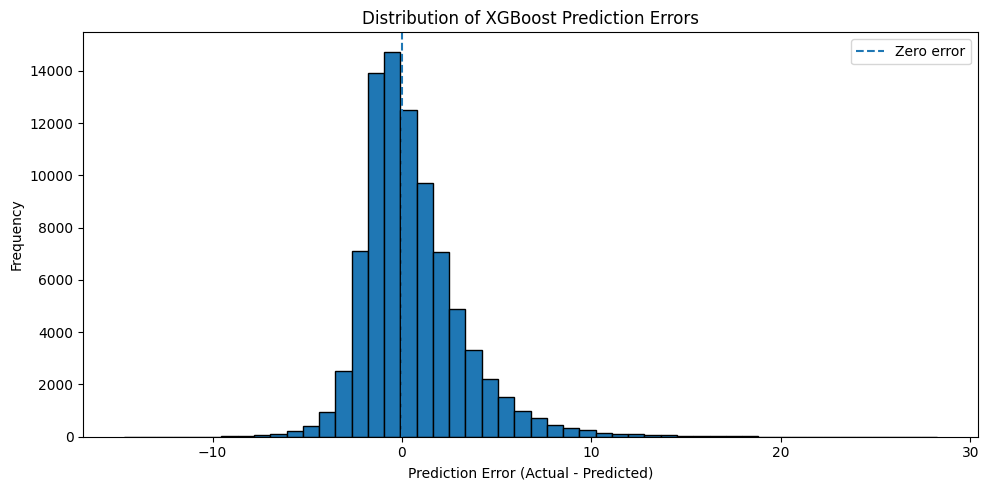

In [149]:
plt.figure(figsize=(10, 5))

plt.hist(test_results['error'],bins=50,edgecolor='black')

plt.axvline(0,linestyle='--',label='Zero error')
plt.title('Distribution of XGBoost Prediction Errors')
plt.xlabel('Prediction Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

**Saving the trained model**

In [151]:
# Save the complete fitted XGBoost pipeline
model_path = '/kaggle/working/tuned_xgboost_pharmacy_demand.joblib'

joblib.dump(
    xgb_search.best_estimator_,
    model_path
)

print("Model saved successfully.")
print(f"Saved location: {model_path}")

Model saved successfully.
Saved location: /kaggle/working/tuned_xgboost_pharmacy_demand.joblib


### Verifying the saved model

In [152]:
# Load the saved model
loaded_xgb_model = joblib.load(model_path)

# Generate predictions using the loaded model
loaded_predictions = loaded_xgb_model.predict(X_test.iloc[:10])

# Compare with the original model predictions
verification = pd.DataFrame({
    'Original_prediction': xgb_test_predictions[:10],
    'Loaded_model_prediction': loaded_predictions
})

verification['difference'] = (
    verification['Original_prediction']
    - verification['Loaded_model_prediction']
)

print("Model loaded successfully.")
print("\nPrediction verification:")
display(verification.round(6))

print(
    "\nPredictions match:",
    np.allclose(
        xgb_test_predictions[:10],
        loaded_predictions
    )
)

Model loaded successfully.

Prediction verification:


,Original_prediction,Loaded_model_prediction,difference
0,17.261158,17.261158,0.0
1,3.587328,3.587328,0.0
2,9.446917,9.446917,0.0
3,3.477902,3.477902,0.0
4,4.103873,4.103873,0.0
5,11.587094,11.587094,0.0
6,7.173727,7.173727,0.0
7,3.328866,3.328866,0.0
8,8.828252,8.828252,0.0
9,3.606504,3.606504,0.0



Predictions match: True
